In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path

In [4]:
df=pd.read_csv("C:\my Files\RiskPredANDMarketEvaluation\data\processed\market_data.csv")
df.head()


,date,ticker,open,high,low,close,adj_close,volume,dividends,stock_splits
0,2021-10-15,AMD,112.510002,112.839996,111.110001,112.120003,112.120003,34203000,0.0,0.0
1,2021-10-18,AMD,111.900002,116.879997,111.370003,116.430000,116.430000,47537800,0.0,0.0
2,2021-10-19,AMD,116.160004,117.169998,114.470001,116.330002,116.330002,39593900,0.0,0.0
3,2021-10-20,AMD,116.290001,118.300003,115.419998,116.389999,116.389999,34244800,0.0,0.0
4,2021-10-21,AMD,116.500000,119.680000,116.260002,119.330002,119.330002,34794900,0.0,0.0


In [5]:
df.tail()

,date,ticker,open,high,low,close,adj_close,volume,dividends,stock_splits
5011,2026-10-08,TSM,466.320007,471.190002,452.880005,457.989990,457.989990,13421700,0.0,0.0
5012,2026-10-09,TSM,464.209991,464.829987,449.750000,453.309998,453.309998,9242000,0.0,0.0
5013,2026-10-12,TSM,453.549988,454.399994,444.350006,444.350006,444.350006,8867200,0.0,0.0
5014,2026-10-13,TSM,439.519989,445.500000,437.399994,445.119995,445.119995,8581100,0.0,0.0
5015,2026-10-14,TSM,436.250000,440.390015,428.059998,430.000000,430.000000,14973600,0.0,0.0


In [6]:
df.shape

(5016, 10)

In [7]:
df.isnull().any()


date            False
ticker          False
open            False
high            False
low             False
close           False
adj_close       False
volume          False
dividends       False
stock_splits    False
dtype: bool

In [8]:
df['date']=pd.to_datetime(df['date'])

date_ranges = df.groupby('ticker')['date'].agg(['min', 'max'])


In [9]:
date_ranges

,min,max
ticker,,
AMD,2021-10-15,2026-10-14
INTC,2021-10-15,2026-10-14
NVDA,2021-10-15,2026-10-14
TSM,2021-10-15,2026-10-14


In [10]:
df[df.duplicated()]

,date,ticker,open,high,low,close,adj_close,volume,dividends,stock_splits


Checking for gaps between trading days..

In [11]:
gap_results = []

for ticker, group in df.groupby("ticker"):
    dates = group["date"].sort_values().drop_duplicates()

    gaps = dates.diff().dt.days

    for i in gaps[gaps > 1].index:
        previous_date = dates.loc[i - 1]
        current_date = dates.loc[i]

        gap_results.append({
            "ticker": ticker,
            "previous_date": previous_date,
            "next_date": current_date,
            "calendar_days_between": (current_date - previous_date).days,
            "weekdays_between": len(
                pd.bdate_range(
                    previous_date + pd.Timedelta(days=1),
                    current_date - pd.Timedelta(days=1)
                )
            )
        })

gaps_df = pd.DataFrame(gap_results)

if not gaps_df.empty:
    display(gaps_df)
else:
    print("No multi-day gaps found.")

,ticker,previous_date,next_date,calendar_days_between,weekdays_between
0,AMD,2021-10-15,2021-10-18,3,0
1,AMD,2021-10-22,2021-10-25,3,0
2,AMD,2021-10-29,2021-11-01,3,0
3,AMD,2021-11-05,2021-11-08,3,0
4,AMD,2021-11-12,2021-11-15,3,0
...,...,...,...,...,...
1095,TSM,2026-09-11,2026-09-14,3,0
1096,TSM,2026-09-18,2026-09-21,3,0
1097,TSM,2026-09-25,2026-09-28,3,0
1098,TSM,2026-10-02,2026-10-05,3,0


divident and stock price

In [12]:
actions = df[
    (df["dividends"].fillna(0) != 0) |
    (df["stock_splits"].fillna(0) != 0)
].copy()

display(
    actions[
        ["date", "ticker", "close", "adj_close",
         "dividends", "stock_splits"]
    ].sort_values(["ticker", "date"])
)

,date,ticker,close,adj_close,dividends,stock_splits
1268,2021-11-04,INTC,50.310001,46.660835,0.348,0.0
1331,2022-02-04,INTC,48.009998,44.866856,0.365,0.0
1393,2022-05-05,INTC,44.599998,42.009567,0.365,0.0
1455,2022-08-04,INTC,35.660000,33.927910,0.365,0.0
1520,2022-11-04,INTC,28.200001,27.192633,0.365,0.0
1582,2023-02-06,INTC,28.690001,28.002228,0.365,0.0
1643,2023-05-04,INTC,31.240000,30.615957,0.125,0.0
1706,2023-08-04,INTC,35.139999,34.561951,0.125,0.0
1771,2023-11-06,INTC,37.950001,37.448460,0.125,0.0
1833,2024-02-06,INTC,42.740002,42.298779,0.125,0.0


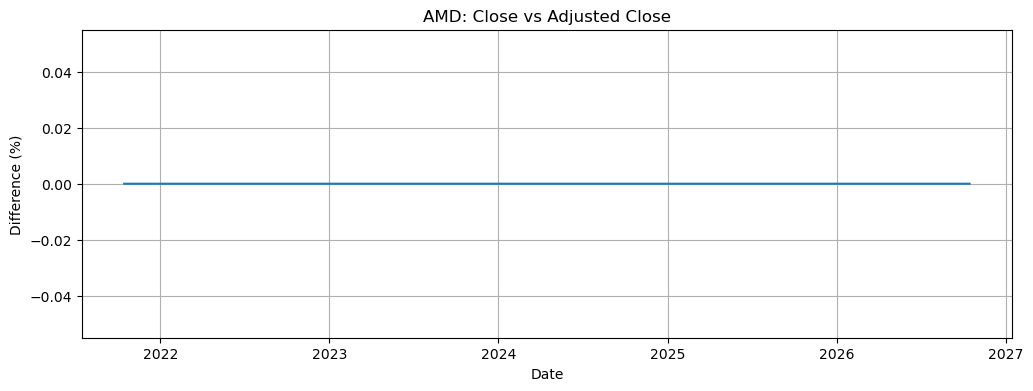

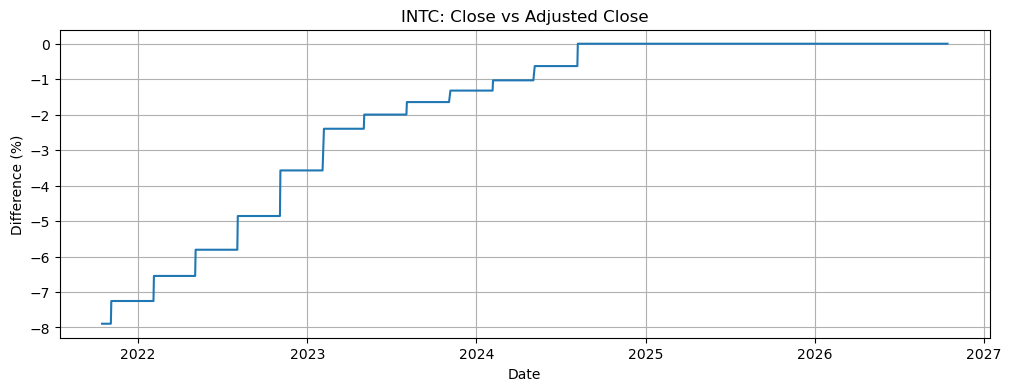

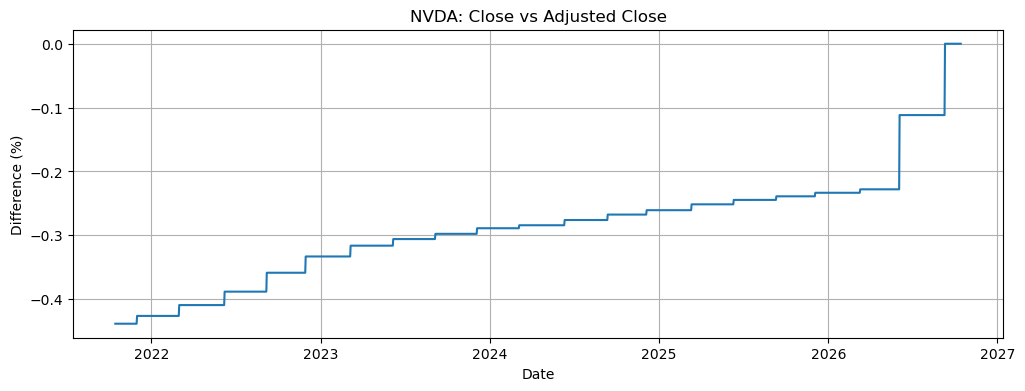

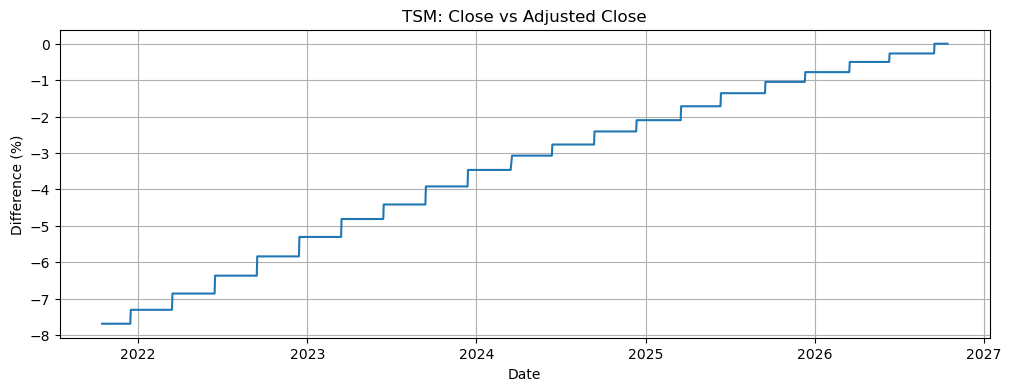

In [13]:
df["close_vs_adj_close_pct"] = (
    (df["adj_close"] / df["close"]) - 1
) * 100

for ticker, group in df.groupby("ticker"):
    plt.figure(figsize=(12, 4))
    plt.plot(
        group["date"],
        group["close_vs_adj_close_pct"]
    )
    plt.title(f"{ticker}: Close vs Adjusted Close")
    plt.xlabel("Date")
    plt.ylabel("Difference (%)")
    plt.grid(True)
    plt.show()

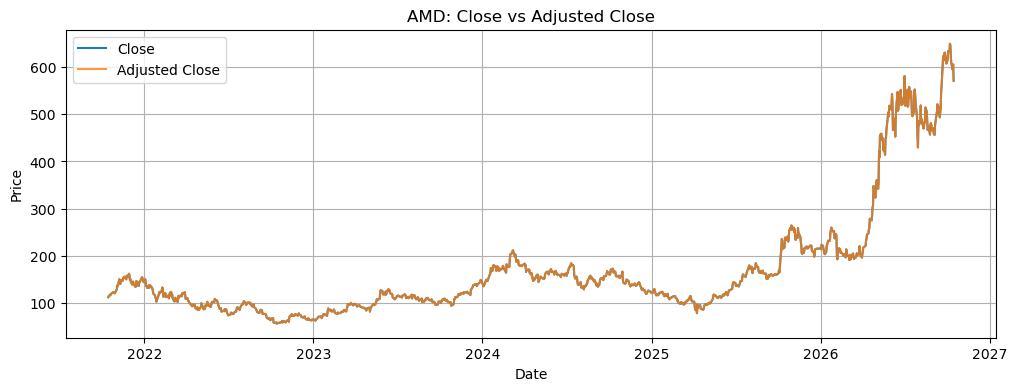

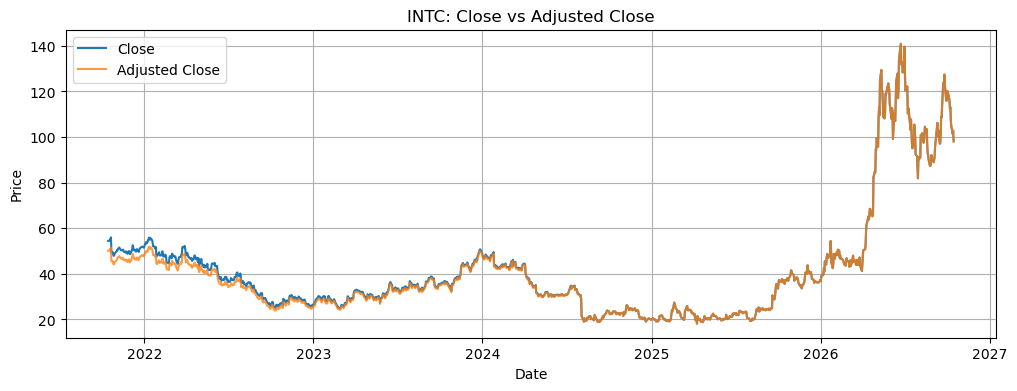

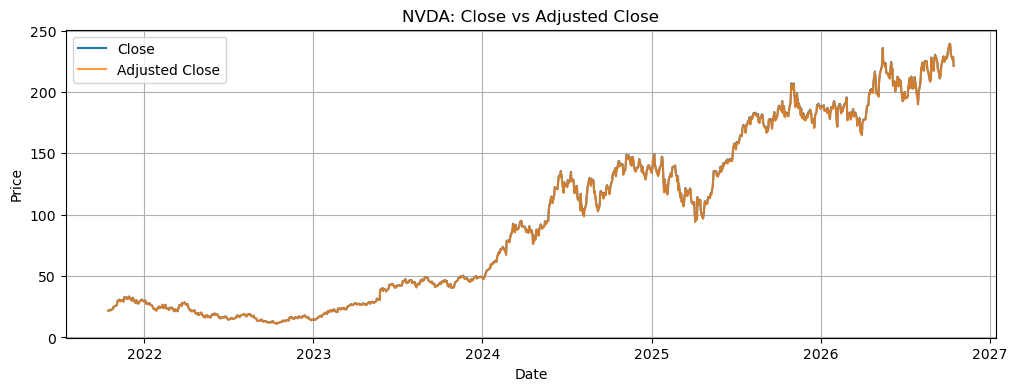

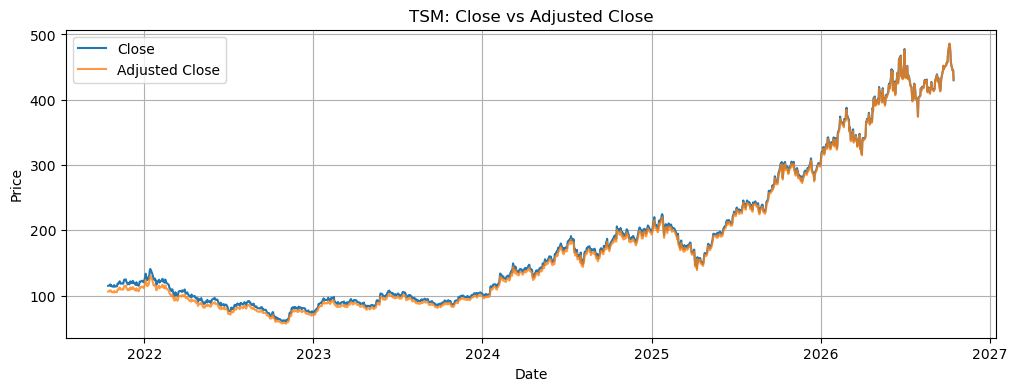

In [14]:
for ticker, group in df.groupby("ticker"):
    group = group.sort_values("date")

    plt.figure(figsize=(12, 4))
    plt.plot(group["date"], group["close"], label="Close")
    plt.plot(
        group["date"],
        group["adj_close"],
        label="Adjusted Close",
        alpha=0.8
    )

    plt.title(f"{ticker}: Close vs Adjusted Close")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.show()

In [15]:
df["daily_return"] = (
    df.groupby("ticker")["adj_close"]
      .pct_change(fill_method=None) * 100
)

display(
    df[["date", "ticker", "adj_close", "daily_return"]].head(10)
)

,date,ticker,adj_close,daily_return
0,2021-10-15,AMD,112.120003,NaN
1,2021-10-18,AMD,116.430000,3.844093
2,2021-10-19,AMD,116.330002,-0.085887
3,2021-10-20,AMD,116.389999,0.051575
4,2021-10-21,AMD,119.330002,2.525992
5,2021-10-22,AMD,119.820000,0.410624
6,2021-10-25,AMD,122.360001,2.119847
7,2021-10-26,AMD,122.930000,0.465838
8,2021-10-27,AMD,122.279999,-0.528757
9,2021-10-28,AMD,121.160004,-0.915927


In [16]:
return_summary = (
    df.groupby("ticker")["daily_return"]
      .agg(
        mean_return="mean",
        median_return="median",
        std_return="std",
        minimum_return="min",
        maximum_return="max"
      )
      .round(3)
)

display(return_summary)

,mean_return,median_return,std_return,minimum_return,maximum_return
ticker,,,,,
AMD,0.195,0.039,3.625,-17.314,23.820
INTC,0.114,-0.022,3.497,-26.059,23.600
NVDA,0.238,0.262,3.272,-16.968,24.370
TSM,0.141,0.020,2.424,-13.327,12.294


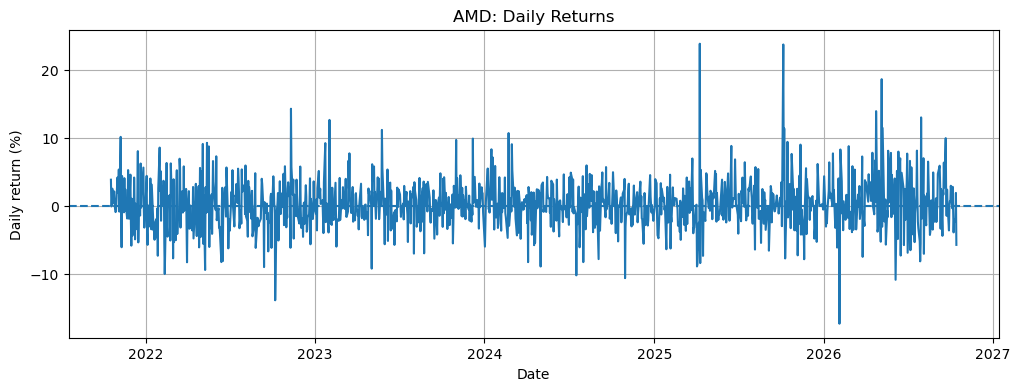

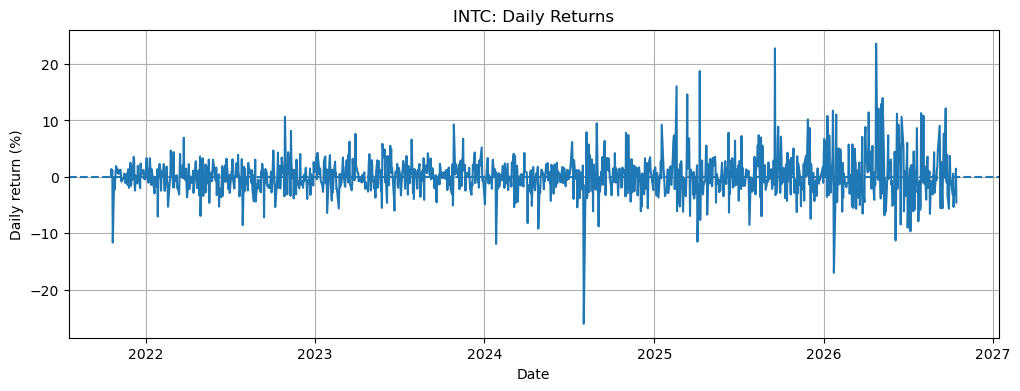

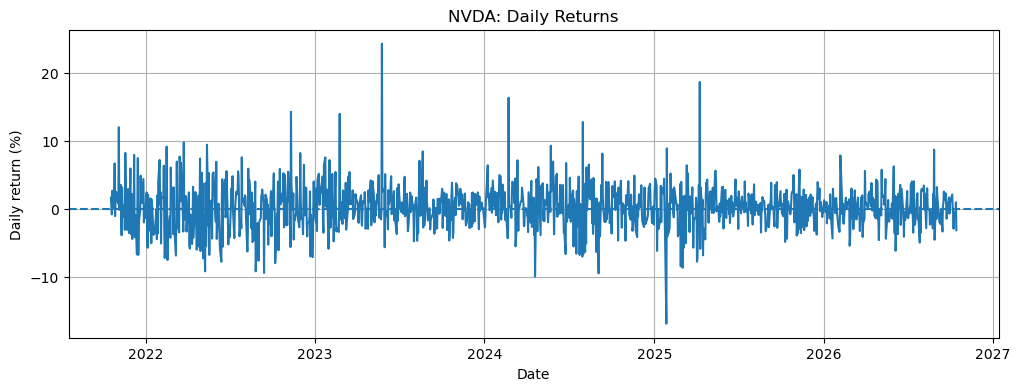

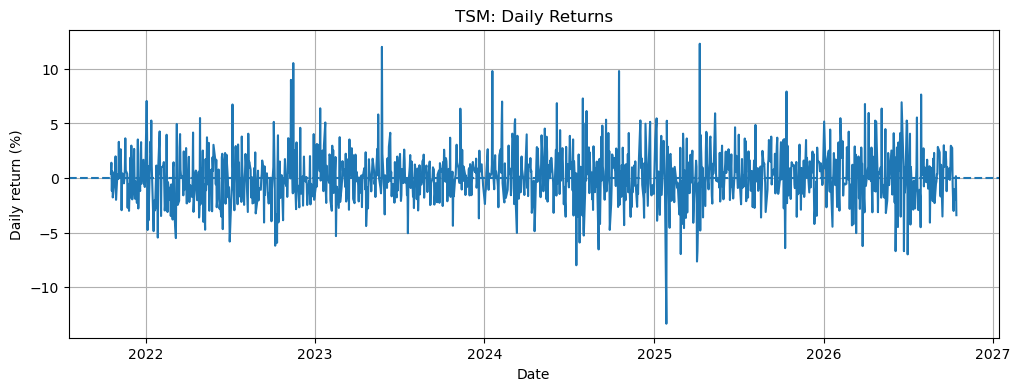

In [17]:
for ticker, group in df.groupby("ticker"):
    plt.figure(figsize=(12, 4))
    plt.plot(group["date"], group["daily_return"])
    plt.axhline(0, linestyle="--")
    plt.title(f"{ticker}: Daily Returns")
    plt.xlabel("Date")
    plt.ylabel("Daily return (%)")
    plt.grid(True)
    plt.show()

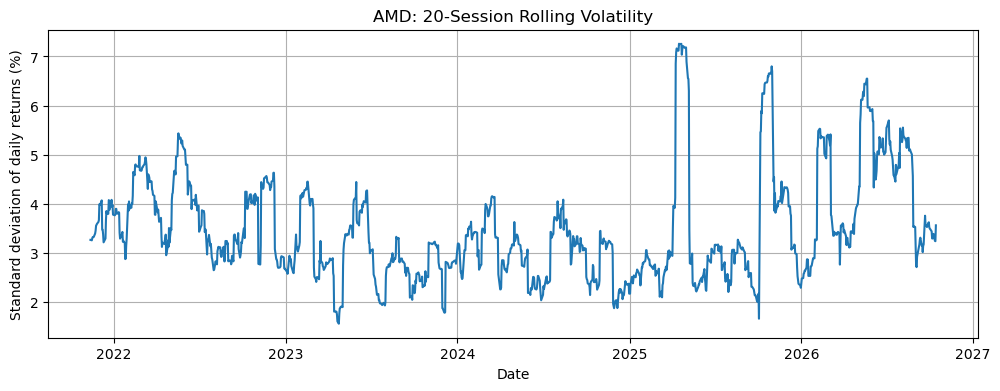

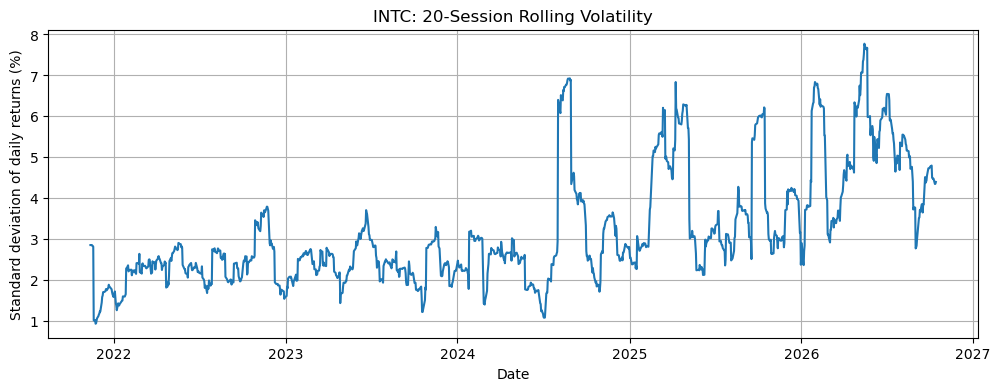

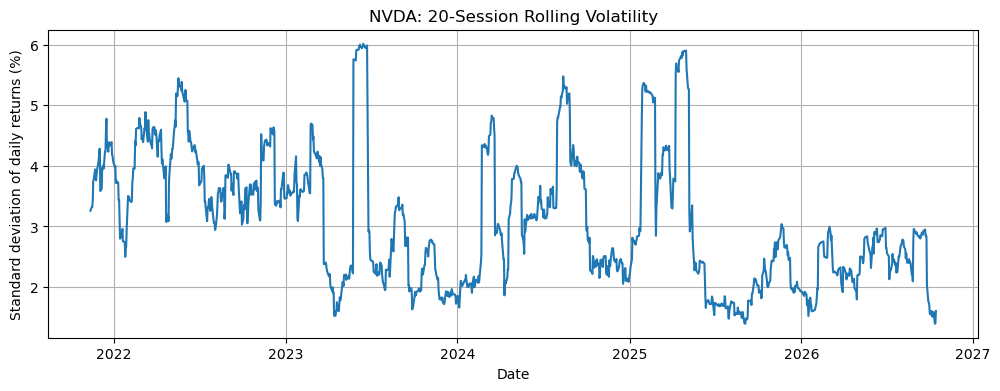

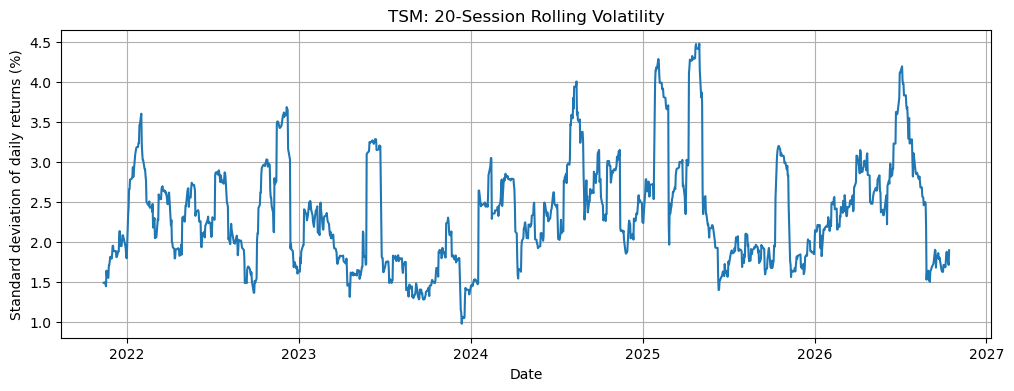

In [18]:
df["rolling_volatility_20d"] = (
    df.groupby("ticker")["daily_return"]
      .transform(lambda s: s.rolling(window=20, min_periods=20).std())
)



for ticker, group in df.groupby("ticker"):
    plt.figure(figsize=(12, 4))
    plt.plot(group["date"], group["rolling_volatility_20d"])
    plt.title(f"{ticker}: 20-Session Rolling Volatility")
    plt.xlabel("Date")
    plt.ylabel("Standard deviation of daily returns (%)")
    plt.grid(True)
    plt.show()

In [19]:
df["running_peak"] = (
    df.groupby("ticker")["adj_close"].cummax()
)

df["drawdown_pct"] = (
    (df["adj_close"] / df["running_peak"] - 1) * 100
)

drawdown_summary = (
    df.groupby("ticker")["drawdown_pct"]
      .min()
      .rename("maximum_drawdown_pct")
      .round(2)
      .to_frame()
)

display(drawdown_summary)

,maximum_drawdown_pct
ticker,
AMD,-65.45
INTC,-65.04
NVDA,-66.34
TSM,-56.47


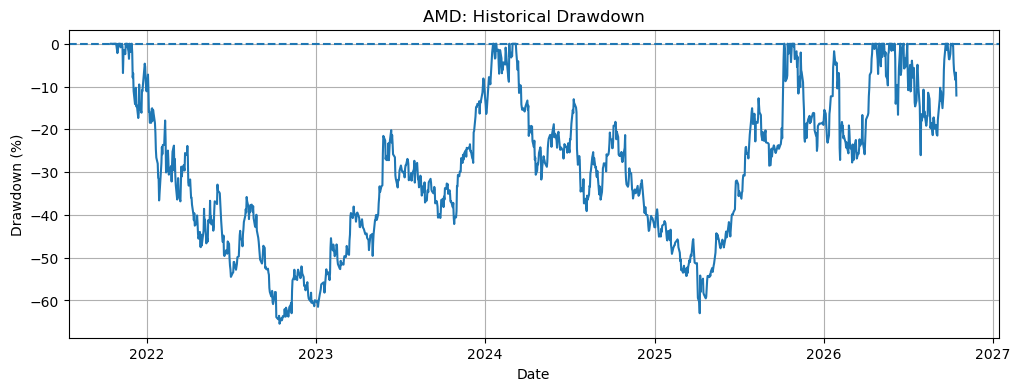

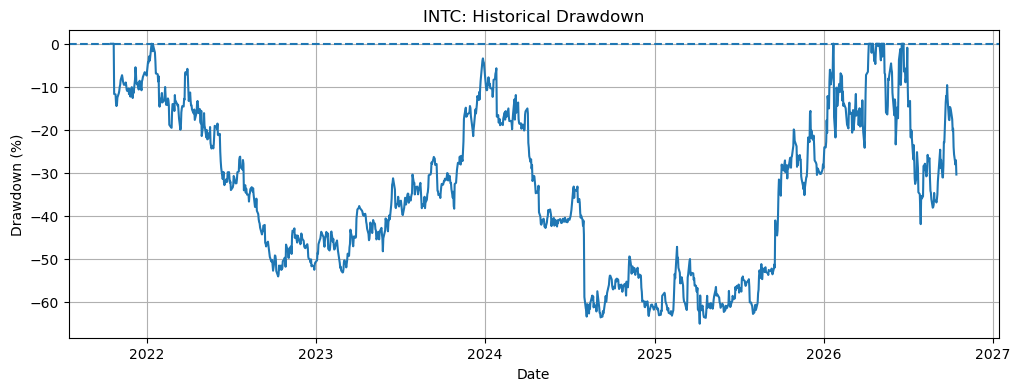

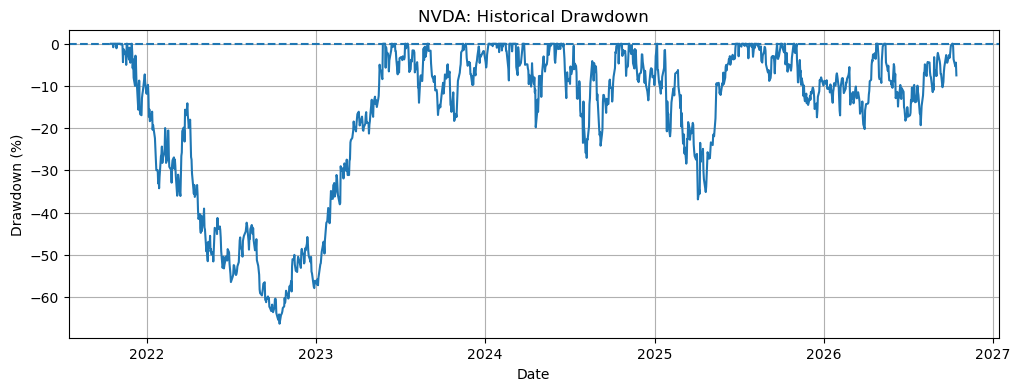

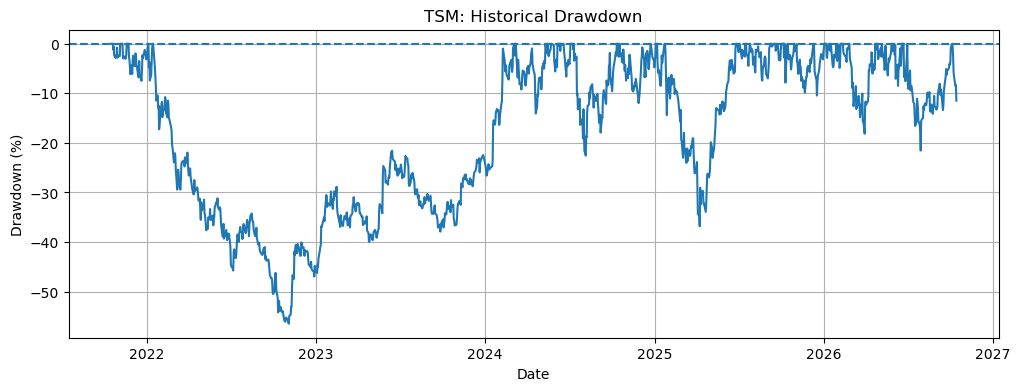

In [20]:
for ticker, group in df.groupby("ticker"):
    plt.figure(figsize=(12, 4))
    plt.plot(group["date"], group["drawdown_pct"])
    plt.axhline(0, linestyle="--")
    plt.title(f"{ticker}: Historical Drawdown")
    plt.xlabel("Date")
    plt.ylabel("Drawdown (%)")
    plt.grid(True)
    plt.show()

In [21]:
HORIZON = 10
THRESHOLD = 0.05  # 5%

def add_stress_target(group):
    group = group.sort_values("date").copy()

    # Future adjusted closes: next 10 trading observations
    future_prices = pd.concat(
        [
            group["adj_close"].shift(-step)
            for step in range(1, HORIZON + 1)
        ],
        axis=1
    )

    # Minimum price during the next 10 sessions
    group["future_min_adj_close_10d"] = future_prices.min(axis=1)

    # Require all 10 future observations to exist
    complete_window = future_prices.notna().all(axis=1)

    # Compare the future minimum against today's adjusted close
    group["stress_event_10d"] = np.nan

    group.loc[complete_window, "stress_event_10d"] = (
        group.loc[complete_window, "future_min_adj_close_10d"]
        <= group.loc[complete_window, "adj_close"] * (1 - THRESHOLD)
    ).astype(int)

    return group

df = (
    df.groupby("ticker", group_keys=False)
      .apply(add_stress_target)
      .reset_index(drop=True)
)

C:\Users\aadib\AppData\Local\Temp\ipykernel_26072\2961029588.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(add_stress_target)


In [22]:
eligible = df.dropna(subset=["stress_event_10d"]).copy()

target_summary = (
    eligible.groupby("ticker")["stress_event_10d"]
    .agg(
        eligible_observations="count",
        stress_events="sum",
        event_rate="mean"
    )
)

target_summary["event_rate_pct"] = (
    target_summary["event_rate"] * 100
)

display(target_summary.round(2))

,eligible_observations,stress_events,event_rate,event_rate_pct
ticker,,,,
AMD,1244,576.0,0.46,46.30
INTC,1244,555.0,0.45,44.61
NVDA,1244,492.0,0.40,39.55
TSM,1244,369.0,0.30,29.66


In [23]:
def calculate_event_rate(group, threshold, horizon=10):
    prices = group.sort_values("date")["adj_close"]

    future_prices = pd.concat(
        [prices.shift(-step) for step in range(1, horizon + 1)],
        axis=1
    )

    complete = future_prices.notna().all(axis=1)

    event = (
        future_prices.min(axis=1)
        <= prices * (1 - threshold)
    )

    return event.loc[complete].mean() * 100

threshold_results = []

for ticker, group in df.groupby("ticker"):
    for threshold in [0.03, 0.05, 0.07]:
        threshold_results.append({
            "ticker": ticker,
            "threshold_pct": threshold * 100,
            "event_rate_pct": calculate_event_rate(group, threshold)
        })

threshold_results = pd.DataFrame(threshold_results)

display(
    threshold_results.pivot(
        index="ticker",
        columns="threshold_pct",
        values="event_rate_pct"
    ).round(2)
)

threshold_pct,3.0,5.0,7.0
ticker,,,
AMD,60.53,46.30,35.45
INTC,58.60,44.61,31.19
NVDA,55.71,39.55,28.46
TSM,47.43,29.66,17.28


In [24]:
output_dir = Path("experiments/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(output_dir / "market_data_with_eda_features.csv", index=False)
return_summary.to_csv(output_dir / "daily_return_summary.csv")
drawdown_summary.to_csv(output_dir / "drawdown_summary.csv")
target_summary.to_csv(output_dir / "stress_target_summary.csv")
threshold_results.to_csv(output_dir / "stress_threshold_comparison.csv", index=False)

print("EDA calculations and summaries saved.")

EDA calculations and summaries saved.
